In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from utils import load_root

ROOT = load_root()
from source.plots import FIGURES_DIR, save_fig
from source.plots import examples as plot_mod

OUT_PNG = FIGURES_DIR / "examples/kink_vs_notch.png"

%load_ext autoreload
%autoreload 2

[utils] Project root loaded successfully: /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2


## Kink vs Notch

In [3]:
rng = np.random.default_rng(2026)
epsilon = 0.3
tau0 = 0.0
tau1 = 0.04
z_star = 10.0
notch_size = 1.5
bins = np.arange(-0.125, 20.001, 0.25)

ability = rng.uniform(1, 20, 200_000)
z_0 = ability * (1 - tau0) ** epsilon

z_kink = np.where(
    z_0 <= z_star,
    z_0,
    np.maximum(z_star, ability * (1 - tau1) ** epsilon),
)
z_notch = np.where(
    (z_0 <= z_star) | (z_0 >= z_star + notch_size),
    z_0,
    z_star,
)

kink_counts, _ = np.histogram(z_kink, bins)
notch_counts, _ = np.histogram(z_notch, bins)

def count_in(counts, lo, hi):
    mask = (bins[:-1] >= lo) & (bins[:-1] < hi)
    return counts[mask].sum()

kink_left = count_in(kink_counts, 9.625, 9.875)
kink_peak = count_in(kink_counts, 9.875, 10.125)
kink_mid = kink_counts[(bins[:-1] >= 12.0) & (bins[:-1] < 15.0)]

notch_peak = count_in(notch_counts, 9.875, 10.125)
notch_rest = notch_counts[(bins[:-1] >= 10.125) & (bins[:-1] < 11.375)]
notch_rest_mean = notch_rest.mean()

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/examples/kink_vs_notch.pdf


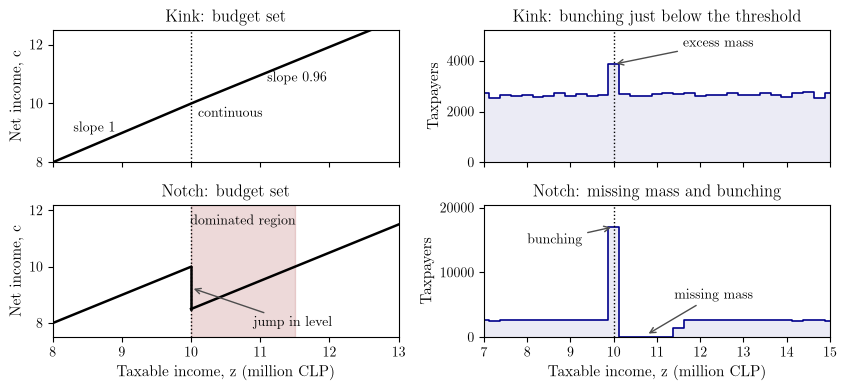

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(8.5, 4), sharex="col")
fig, axes = plot_mod.plot_kink_vs_notch(
    bins, kink_counts, notch_counts, fig, axes,
    z_star=z_star, notch_size=notch_size, tau1=tau1,
)

save_fig(FIGURES_DIR / "examples/kink_vs_notch.pdf", fig)
fig.savefig(OUT_PNG, dpi=130, bbox_inches="tight")


## Utility Appendix A

In [5]:
n = 1.0  # normalized utility (n = 1 => z = n reference point - no taxes)
z = np.linspace(0, 1.5, 400)  # ingreso tributable
epsilons = [0.2, 0.5, 1.0, 2.0] # elasticities


saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/disutility_curvature.pdf


PosixPath('/home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/disutility_curvature.pdf')

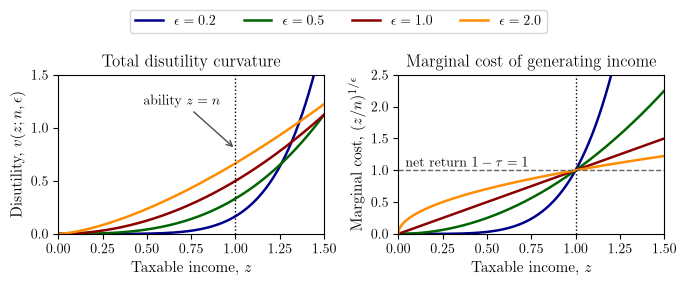

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5))
z = np.linspace(0, 1.5, 400)
plot_mod.plot_disutility_curvature(z, fig, axes)
save_fig(FIGURES_DIR / "disutility_curvature.pdf", fig)

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/directional_utility_kink.pdf


PosixPath('/home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/directional_utility_kink.pdf')

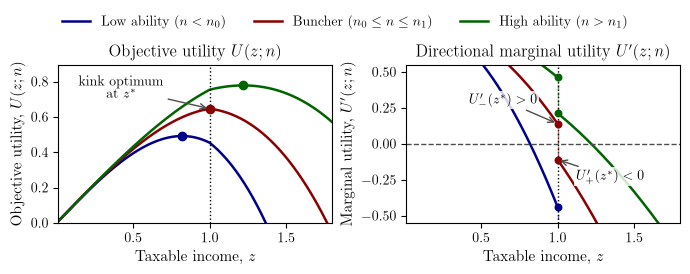

In [12]:
# 1. Parámetros estructurales y grilla
z = np.linspace(0.01, 1.8, 500)
z_star = 1.0
tau0 = 0.10
tau1 = 0.35
eps = 0.5

# 2. Restricción presupuestaria con kink y tasas marginales netas
c = np.where(z <= z_star, (1.0 - tau0) * z, (1.0 - tau0) * z_star + (1.0 - tau1) * (z - z_star))
net_rate = np.where(z <= z_star, 1.0 - tau0, 1.0 - tau1)

# 3. Habilidades frontera del intervalo de bunching [n0, n1]
n0 = z_star * (1.0 - tau0) ** (-eps)
n1 = z_star * (1.0 - tau1) ** (-eps)

types_spec = [
    (0.82 * n0, r"Low ability ($n < n_0$)", "darkblue"),
    (0.5 * (n0 + n1), r"Buncher ($n_0 \le n \le n_1$)", "darkred"),
    (1.22 * n1, r"High ability ($n > n_1$)", "darkgreen"),
]

# 4. Cálculo de trayectorias para cada tipo
trajectories = []
for n_val, label, color in types_spec:
    disutility = (n_val / (1.0 + 1.0 / eps)) * (z / n_val) ** (1.0 + 1.0 / eps)
    utility = c - disutility
    marginal_u = net_rate - (z / n_val) ** (1.0 / eps)
    opt_idx = np.argmax(utility)

    trajectories.append({
        "label": label,
        "color": color,
        "utility": utility,
        "marginal_u": marginal_u,
        "z_opt": z[opt_idx],
        "u_opt": utility[opt_idx],
        "u_prime_left": (1.0 - tau0) - (z_star / n_val) ** (1.0 / eps),
        "u_prime_right": (1.0 - tau1) - (z_star / n_val) ** (1.0 / eps),
    })

# 5. Ploteo y guardado
fig, axes = plt.subplots(1, 2, figsize=(7, 2.5))
plot_mod.plot_directional_utility_kink(z, trajectories, fig, axes, z_star=z_star)
save_fig(FIGURES_DIR / "directional_utility_kink.pdf", fig)

saved figure to /home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/excess_mass_identification.pdf


PosixPath('/home/choroy/Documents/doctorado/S4/ENECO894/problem-set-2/output/figures/excess_mass_identification.pdf')

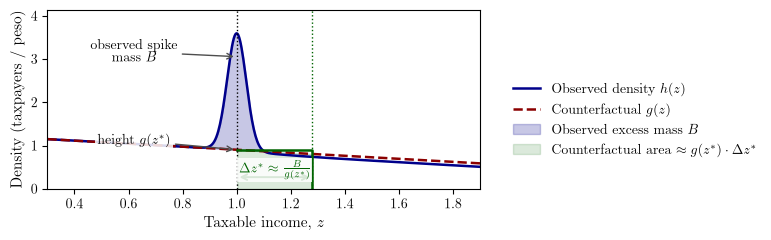

In [28]:
# 1. Parámetros y grilla
z = np.linspace(0.3, 1.9, 500)
z_star = 1.0
delta_z = 0.28

# 2. Densidad contrafactual suave g(z) (ligeramente decreciente, como en datos reales)
g_cf = 1.15 - 0.35 * (z - 0.3)

# 3. Densidad observada h(z): sigue g(z) en los vecinos, tiene un pico en z* y cae a la derecha
sigma_bunch = 0.035
B_area = np.trapezoid(g_cf[(z >= z_star) & (z <= z_star + delta_z)], z[(z >= z_star) & (z <= z_star + delta_z)])
spike = (B_area / (sigma_bunch * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((z - z_star) / sigma_bunch) ** 2)

# Desplazamiento a la izquierda por encima del umbral (missing mass en el tramo alto)
shift_down = np.where(z > z_star + 0.05, 0.08 * (1 - np.exp(-(z - z_star) / 0.15)), 0.0)
h_obs = g_cf + spike - shift_down

# 4. Ploteo y guardado
fig, ax = plt.subplots(1, 1, figsize=(5, 2.5))
plot_mod.plot_excess_mass_identification(z, g_cf, h_obs, z_star, delta_z, fig, ax)
save_fig(FIGURES_DIR / "excess_mass_identification.pdf", fig)